# 04 · Expression — EMT-transcription-factor axis along the trajectory

*(Renumbered from 06: with Gate 2 = GO / Gate 3 = NA the manifold is non-branching, so the
branching-only correlation (04) and module (05) notebooks are **not** produced; the unconditional EMT-TF
expression step is the final notebook.)*

The EMT-TF panel is scored **on this dataset**, gated on detectable expression, and drawn from Snail /
Zeb / Twist **plus** the mesenchymal FOXC and PRRX families. CLL is a lymphoid blood malignancy, so most
canonical EMT-TFs are silent — only factors clearing a 3% detection floor are read out. The overlay is a
**categorical** display of thresholded expressers on a grey manifold (reference style), not a continuous
single-gene colormap. Deliverable: `expression.pdf`.

In [1]:
import os, sys, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
from scipy.stats import spearmanr
import scipy.sparse as sp
import matplotlib.pyplot as plt
sc.settings.verbosity = 0

In [2]:
name = os.path.basename(os.getcwd()); category = os.path.basename(os.path.dirname(os.getcwd()))
pth = os.path.join(*(['..']*4))
pth_in  = os.path.join(pth, 'data', 'cancer', 'vertebrate', 'CCCA', 'claude', category, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', category, name)
adata = sc.read_h5ad(os.path.join(pth_in, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']  # house linear layout
t = adata.obs['t'].values; tn = (t - t.min()) / (t.max() - t.min())
print('cells:', adata.shape[0], '| pseudotime range %.2f -> %.2f' % (t.min(), t.max()))

cells: 18314 | pseudotime range 0.00 -> 21.49


### Derive the end-specific EMT-TFs (data-driven)
For each candidate TF: fraction of cells expressing it, mean expression in the early (root) vs late
(terminus) pseudotime tercile, and Spearman correlation with pseudotime. Factors below a 3% detection
floor are excluded (an unreadable overlay). Expression is read from `adata.raw` (all genes).

In [3]:
cand = ['SNAI1','SNAI2','TWIST1','TWIST2','ZEB1','ZEB2','FOXC1','FOXC2','PRRX1','PRRX2']
cand = [g for g in cand if g in adata.raw.var_names]
Xr = adata.raw[:, cand].X; Xd = Xr.toarray() if sp.issparse(Xr) else np.asarray(Xr)
lo, hi = np.quantile(t, [0.333, 0.667]); rows = []
for i, g in enumerate(cand):
    v = Xd[:, i]; rho, _ = spearmanr(t, v)
    rows.append((g, (v>0).mean(), v[t<=lo].mean(), v[t>=hi].mean(), rho))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_t']).sort_values('frac_expr', ascending=False)
print(df.round(3).to_string(index=False))
expr = df[df.frac_expr >= 0.03].TF.tolist()
print('\nexpressed (>=3% floor):', expr)
# order end-labels by pseudotime trend among expressed
early_tf, late_tf = expr[0], (expr[1] if len(expr) > 1 else expr[0])
print('panel:', early_tf, '(more abundant),', late_tf)

   TF  frac_expr  mean_early  mean_late  rho_t
 ZEB2      0.121       0.072      0.060 -0.006
 ZEB1      0.038       0.020      0.019  0.010
SNAI1      0.000       0.000      0.001  0.017
FOXC1      0.000       0.000      0.000 -0.002
PRRX1      0.000       0.000      0.000 -0.009

expressed (>=3% floor): ['ZEB2', 'ZEB1']
panel: ZEB2 (more abundant), ZEB1


### EMT-TF expression overlay (deliverable)
House style: `figsize=(3.5,1.5)`, pseudotime left->right, `size=30`. **Categorical** overlay of thresholded
expressers (upper quartile among expressing cells) on a grey manifold — the more abundant factor drawn
first so the sparser reads on top. Not a continuous colormap; consistent marker size with the other
panels.

ZEB2: 12.1% expressing; 554 shown (upper quartile), mean pseudotime of shown = 0.37
ZEB1: 3.8% expressing; 174 shown (upper quartile), mean pseudotime of shown = 0.38
EMT-TFs shown: ZEB2, ZEB1 | saved expression.pdf


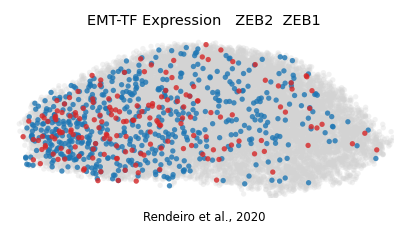

In [4]:
xl = adata.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
def vec(g):
    x = adata.raw[:, g].X; return x.toarray().ravel() if sp.issparse(x) else np.asarray(x).ravel()
panel = expr[:2] if len(expr) >= 2 else expr
thr = {g: (float(np.quantile(vec(g)[vec(g)>0], 0.75)) if (vec(g)>0).any() else 0.0) for g in panel}
sel = {g: vec(g) > thr[g] for g in panel}
order = sorted(panel, key=lambda g: -int(sel[g].sum()))
colors = {panel[0]: 'tab:blue', panel[-1]: 'tab:red'} if len(panel)>1 else {panel[0]:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
lab = '  '.join(f'{g}' for g in panel)
ax.set_title('EMT-TF Expression   ' + lab, size=7.5)
ax.text(.5, -.14, 'Rendeiro et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'expression.pdf'), bbox_inches='tight'); plt.show()
for g in panel:
    print(f'{g}: {(vec(g)>0).mean()*100:.1f}% expressing; {int(sel[g].sum())} shown (upper quartile), '
          f'mean pseudotime of shown = {tn[sel[g]].mean():.2f}')
print('EMT-TFs shown:', ', '.join(panel), '| saved expression.pdf')